# **Healthcare Insurance Cost Analysis — Statistical Analysis & Hypothesis Testing**

## Objectives

The objectives of this notebook are to:

- Apply statistical hypothesis testing to the healthcare insurance dataset.
- Test the research questions and hypotheses defined for the project.
- Determine whether observed differences or relationships are statistically significant.
- Use appropriate parametric or non-parametric statistical tests based on the characteristics of the data.
- Interpret statistical results in relation to the healthcare insurance business problem.
- Summarise the statistical findings and their implications for the subsequent machine learning analysis.

## Inputs

This notebook uses the following inputs:

- The cleaned healthcare insurance dataset produced during the ETL and exploratory data analysis stage.
- The findings from the exploratory data analysis, which are used to inform the selection and interpretation of statistical tests.

The cleaned dataset is stored at:

`output/cleaned_insurance.csv`

The statistical analysis will use a significance level of α = 0.05 when evaluating the hypotheses.

## Outputs

This notebook will produce:

- Statistical test results for the defined research questions and hypotheses.
- Appropriate test statistics and p-values for each hypothesis.
- Decisions regarding the null hypotheses using the selected significance level.
- Interpretation of statistically significant and non-significant results.
- Post-hoc analysis where required following significant multi-group tests.
- A summary table of the statistical results.
- Overall statistical conclusions that can be used to support the later machine learning and business analysis stages.

The results will be interpreted in the context of the healthcare insurance business problem and will distinguish statistical association from causation.

## 1.1 Initialising the Project

This notebook is stored in the `notebooks` directory. The working directory is changed to the main project directory so that project files can be accessed using relative paths.

In [29]:
# Set the working directory to the main project folder
import os
project_dir = r"D:\Code\Assessment 3\Assessment-3-Healthcare-Insurance"

os.chdir(project_dir)

# Check the new working directory
print(os.getcwd())

D:\Code\Assessment 3\Assessment-3-Healthcare-Insurance


## 1.2 Import Libraries

In [30]:
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical tests
from scipy import stats

print("Libraries imported successfully.")

Libraries imported successfully.


### 1.3 Loading the Cleaned Dataset

The cleaned dataset produced during the ETL and exploratory data analysis stage is loaded for statistical analysis.

The original raw dataset is not modified. The statistical analysis uses the cleaned dataset stored in the project's `data` directory.

In [31]:
# Load the cleaned dataset
data = pd.read_csv("output/cleaned_insurance.csv")

# Display the first five rows
data.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,Overweight
1,18,male,33.770,1,no,southeast,1725.55230,Obese
2,28,male,33.000,3,no,southeast,4449.46200,Obese
3,33,male,22.705,0,no,northwest,21984.47061,Normal
4,32,male,28.880,0,no,northwest,3866.85520,Overweight


### Stage 1.4 — Final Data Readiness Check

Before calculating descriptive statistics, we will confirm that the dataset contains the required variables and that the numerical columns are stored in the correct format. This helps us identify problems before starting the analysis.

In [32]:

# Check the variables required for our analysis
required_columns = ["age", "bmi", "smoker", "charges"]

missing_columns = [
    column for column in required_columns
    if column not in data.columns
]

if missing_columns:
    print("Missing required columns:", missing_columns)
else:
    print("All required columns are available.")

# Check the data types of the key variables
print("\nKey variable data types:")
print(data[required_columns].dtypes)

# Check missing values in the key variables
print("\nMissing values in key variables:")
print(data[required_columns].isnull().sum())


All required columns are available.

Key variable data types:
age          int64
bmi        float64
smoker      object
charges    float64
dtype: object

Missing values in key variables:
age        0
bmi        0
smoker     0
charges    0
dtype: int64


## Stage 2 — Descriptive Statistics

### Stage 2.1 — Numerical Variables

Before testing our hypotheses, we need to understand the main numerical characteristics of the insurance dataset.

We will calculate summary statistics for age, BMI, number of children, and insurance charges. These statistics will help us understand typical values, variability, and the spread of the data.

This is a descriptive analysis; we are not testing any hypotheses yet.

In [33]:

# Select the numerical variables
numerical_columns = ["age", "bmi", "children", "charges"]

# Calculate descriptive statistics
descriptive_stats = data[numerical_columns].describe().T

# Add skewness to understand distribution shape
descriptive_stats["skewness"] = data[numerical_columns].skew()

# Display the results
display(descriptive_stats.round(2))


,count,mean,std,min,25%,50%,75%,max,skewness
age,1337.0,39.22,14.04,18.00,27.00,39.00,51.00,64.00,0.05
bmi,1337.0,30.66,6.10,15.96,26.29,30.40,34.70,53.13,0.28
children,1337.0,1.10,1.21,0.00,0.00,1.00,2.00,5.00,0.94
charges,1337.0,13279.12,12110.36,1121.87,4746.34,9386.16,16657.72,63770.43,1.52


### Interpretation of Numerical Descriptive Statistics

The dataset contains 1,337 observations. The mean age is 39.22 years, while the mean BMI is 30.66. The number of children has a mean of 1.10 and a median of 1.

Insurance charges show considerable variability, with a mean of 13,279.12 and a median of 9,386.16. The positive skewness of 1.52 indicates that the distribution of charges is strongly right-skewed. This suggests that a smaller number of policyholders have particularly high insurance charges.

These findings are important when selecting statistical methods. We will consider the skewed distribution of charges when comparing smokers and non-smokers and when examining associations between charges, age, and BMI.

### Stage 2.2 — Categorical Variables

In this stage, we will examine the categorical variables in the insurance dataset. We will calculate the number and percentage of observations in each category.

This will help us understand the composition of the dataset, particularly the numbers of smokers and non-smokers, before carrying out the hypothesis tests.

In [34]:

# Select the categorical variables
categorical_columns = ["sex", "smoker", "region", "bmi_category"]

# Display counts and percentages for each variable
for column in categorical_columns:
    print(f"\n{column.upper()}")

    counts = data[column].value_counts(dropna=False)
    percentages = data[column].value_counts(
        normalize=True, dropna=False
    ) * 100

    summary = pd.DataFrame({
        "Count": counts,
        "Percentage (%)": percentages.round(2)
    })

    display(summary)



SEX


,Count,Percentage (%)
sex,,
male,675,50.49
female,662,49.51



SMOKER


,Count,Percentage (%)
smoker,,
no,1063,79.51
yes,274,20.49



REGION


,Count,Percentage (%)
region,,
southeast,364,27.23
southwest,325,24.31
northwest,324,24.23
northeast,324,24.23



BMI_CATEGORY


,Count,Percentage (%)
bmi_category,,
Obese,704,52.66
Overweight,386,28.87
Normal,226,16.90
Underweight,21,1.57


## Stage 3 — Hypothesis  1: Smoking Status and Insurance Charges

### Research question

Do insurance charges differ between smokers and non-smokers?

Smoking status divides policyholders into two independent groups. We will compare their insurance charges to investigate whether the observed difference is statistically significant.

We will use a significance level of 0.05. The null hypothesis assumes that the two groups have the same charge distributions, while the alternative hypothesis states that their distributions differ.

**Null hypothesis (H₀):** Insurance charges have the same distribution for smokers and non-smokers.

**Alternative hypothesis (H₁):** Insurance charges have different distributions for smokers and non-smokers.

**Significance level:** α = 0.05

In [35]:

# Summarise insurance charges by smoking status
smoker_summary = data.groupby("smoker")["charges"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(smoker_summary.round(2))


,count,mean,median,std,min,max
smoker,,,,,,
no,1063,8440.66,7345.73,5992.97,1121.87,36910.61
yes,274,32050.23,34456.35,11541.55,12829.46,63770.43


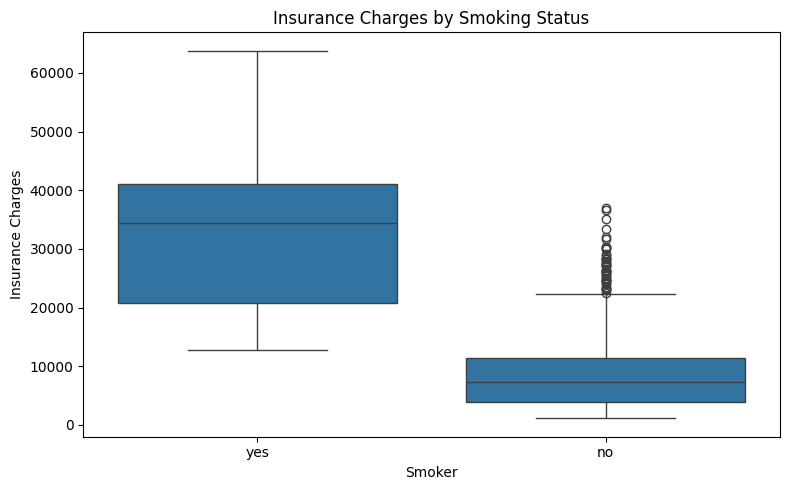

In [36]:

# Compare insurance charges by smoking status
plt.figure(figsize=(8, 5))

sns.boxplot(data=data, x="smoker", y="charges")

plt.title("Insurance Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Insurance Charges")
plt.tight_layout()
plt.show()


### Interpretation: Insurance Charges by Smoking Status

The box plot shows a clear difference in insurance charges between smokers and non-smokers. Smokers have a substantially higher median charge (approximately £34,000) than non-smokers (approximately £7,000).

The distribution of charges among smokers is also much higher overall. Non-smokers have several high-charge outliers, but these remain below the typical charges observed among smokers.

These findings suggest a strong association between smoking status and insurance charges. This is consistent with the Mann–Whitney U test, which identified a statistically significant difference in charges between the two groups (\(p < 0.001\)).

However, this comparison does not establish causation or account for other factors, such as age and BMI.

### Stage 3.3 — Statistical Hypothesis Test

We will use the Mann–Whitney U test to compare insurance-charge distributions for smokers and non-smokers.

We will use a two-sided test with a significance level of 0.05.

- **H₀:** The charge distributions are the same for smokers and non-smokers.
- **H₁:** The charge distributions differ between smokers and non-smokers.

We will report the U statistic and p-value. The test evaluates differences in distributions; it does not automatically establish a difference in medians if the distribution shapes differ.

In [37]:

# Separate insurance charges into two independent groups
non_smoker_charges = data.loc[
    data["smoker"] == "no", "charges"
]

smoker_charges = data.loc[
    data["smoker"] == "yes", "charges"
]

# Perform a two-sided Mann–Whitney U test
u_statistic, p_value = stats.mannwhitneyu(
    non_smoker_charges,
    smoker_charges,
    alternative="two-sided"
)

print(f"Mann–Whitney U statistic: {u_statistic:.2f}")
print(f"P-value: {p_value:.6g}")

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
else:
    print("Decision: Fail to reject the null hypothesis.")





Mann–Whitney U statistic: 7403.00
P-value: 5.74701e-130
Decision: Reject the null hypothesis.


### Results: Smoking Status and Insurance Charges

The Mann–Whitney U test was used to compare insurance-charge distributions between smokers and non-smokers. The significance level was set at 0.05.

The test produced a U statistic of 7,403 and a p-value of approximately \(5.75 \times 10^{-130}\).

Since the p-value is much smaller than 0.05, the null hypothesis is rejected. The results provide strong statistical evidence that insurance-charge distributions differ between smokers and non-smokers.

### Interpretation

The descriptive statistics show that smokers have substantially higher observed insurance charges than non-smokers. The median charge was 34,456.35 for smokers, compared with 7,345.73 for non-smokers.

The Mann–Whitney U test confirms that the difference in the distributions is statistically significant. This suggests that smoking status is an important variable to consider when analysing insurance costs.

However, the analysis identifies an association rather than proving that smoking causes higher charges. Other factors, such as age and BMI, may also contribute to differences in insurance costs.

## Stage 4 — Hypothesis 2: Age and Insurance Charges

### Research question

Is age associated with insurance charges?

We will investigate whether insurance charges tend to increase or decrease as age increases. First, we will visualise the relationship using a box plot. Then, we will use Spearman's rank correlation to measure the direction and strength of the association.

Spearman's correlation is suitable for examining a monotonic relationship without requiring the variables to follow normal distributions.

We will use a significance level of 0.05.

**Null hypothesis (H₀):** There is no monotonic association between age and insurance charges in the population.

**Alternative hypothesis (H₁):** There is a monotonic association between age and insurance charges in the population.

**Significance level:** α = 0.05

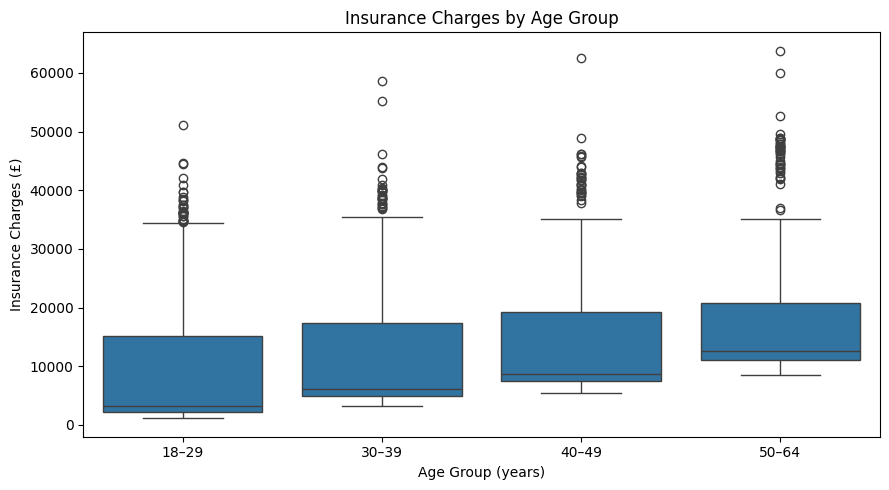

In [38]:


# Create age groups for visualisation
data["age_group"] = pd.cut(
    data["age"],
    bins=[17, 29, 39, 49, 64],
    labels=["18–29", "30–39", "40–49", "50–64"]
)

# Compare insurance charges by age group
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data,
    x="age_group",
    y="charges",
    order=["18–29", "30–39", "40–49", "50–64"]
)

plt.title("Insurance Charges by Age Group")
plt.xlabel("Age Group (years)")
plt.ylabel("Insurance Charges (£)")
plt.tight_layout()
plt.show()



### Interpretation: Insurance Charges by Age Group

The box plot shows a general increase in median insurance charges across the age groups, from 18–29 to 50–64. The 18–29 group has the lowest median charges, while the 50–64 group has the highest.

The distributions are relatively wide, with numerous high-charge outliers in every age group. This indicates substantial variation in insurance costs among individuals of similar ages. However, age-group differences alone do not explain all the variation, as other factors, such as smoking status and BMI, may also be associated with insurance charges.

Overall, the plot suggests a positive association between age and insurance charges. This is consistent with the positive Spearman correlation observed in the statistical analysis, although the box plot alone does not establish causation.

### Stage 4.2 — Spearman's Correlation Test

We will calculate Spearman's rank correlation coefficient between age and insurance charges.

The coefficient, \(\rho\) (rho), ranges from −1 to +1:

- A positive value indicates that charges tend to increase as age increases.
- A negative value indicates that charges tend to decrease as age increases.
- A value near zero indicates little or no monotonic association.

We will also calculate the p-value to determine whether the observed association is statistically significant at the 5% level.

In [39]:

# Calculate Spearman's rank correlation
spearman_rho, p_value = stats.spearmanr(
    data["age"],
    data["charges"]
)

print(f"Spearman correlation (rho): {spearman_rho:.4f}")
print(f"P-value: {p_value:.6g}")

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
else:
    print("Decision: Fail to reject the null hypothesis.")

age_result = stats.spearmanr(data["age"], data["charges"])


Spearman correlation (rho): 0.5335
P-value: 3.18776e-99
Decision: Reject the null hypothesis.


###  Results: Age and Insurance Charges

Spearman's rank correlation was used to investigate the association between age and insurance charges.

The analysis produced a correlation coefficient of 0.5335 and a p-value of approximately \(3.19 \times 10^{-99}\).

Since the p-value is smaller than the significance level of 0.05, the null hypothesis is rejected. The results provide strong statistical evidence of a positive monotonic association between age and insurance charges.

###  Interpretation

The results indicate a positive, moderately strong monotonic association between age and insurance charges. In this dataset, older policyholders generally tend to have higher insurance charges.

The very small p-value indicates that this association is statistically significant at the 5% level. Age may therefore be a useful variable to consider when analysing insurance costs and developing a predictive model.

However, correlation does not prove causation. The relationship may also reflect other factors, including smoking status and BMI. This analysis examines the association between age and charges without controlling for those variables.

## Stage 5 — Hypothesis 3: BMI and Insurance Charges

### Research question

Is BMI associated with insurance charges?

We will investigate whether insurance charges tend to increase or decrease as BMI increases. First, we will create a box plot to examine the relationship. We will then use Spearman's rank correlation to measure the direction and strength of the association.

Spearman's correlation is appropriate for investigating a monotonic relationship without requiring normally distributed variables.

We will use a significance level of 0.05.

**Null hypothesis (H₀):** There is no monotonic association between BMI and insurance charges in the population.

**Alternative hypothesis (H₁):** There is a monotonic association between BMI and insurance charges in the population.

**Significance level:** α = 0.05

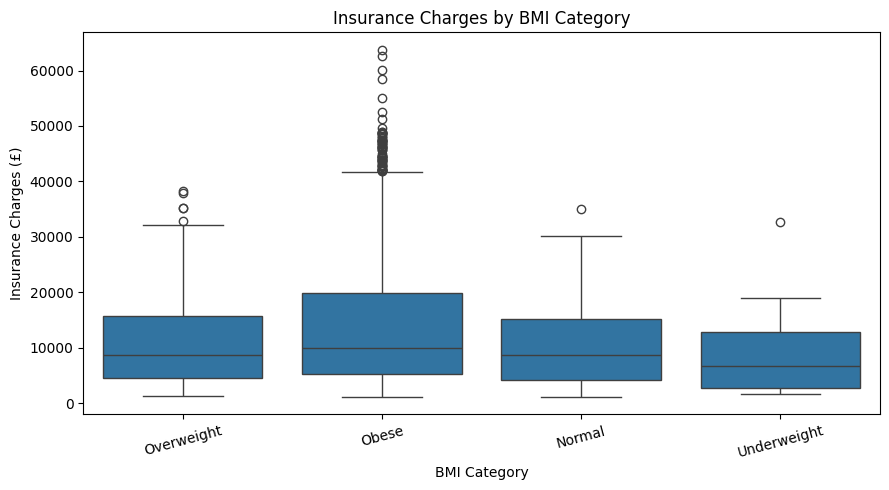

In [40]:

# Compare insurance charges by BMI category
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data,
    x="bmi_category",
    y="charges"
)

plt.title("Insurance Charges by BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Insurance Charges (£)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Interpretation: Insurance Charges by BMI Category

The box plot compares insurance charges across four BMI categories: underweight, normal, overweight, and obese.

The obese group has the highest median insurance charges, while the underweight group has the lowest. The overweight and normal groups have similar median charges. The obese category also contains numerous high-charge outliers, including some exceeding £60,000.

There is substantial variation in insurance charges within each BMI category, and the distributions overlap. Therefore, BMI category alone does not explain all differences in insurance costs. Other factors, particularly smoking status and age, may also contribute to the observed variation.

Overall, the plot suggests differences in insurance charges across BMI categories. However, these differences represent associations rather than evidence of causation.

### Stage 5.2 — Spearman's Correlation Test

We will calculate Spearman's rank correlation coefficient between BMI and insurance charges.

The coefficient ranges from −1 to +1. Positive values indicate that higher BMI tends to be associated with higher charges, while negative values indicate that higher BMI tends to be associated with lower charges.

We will also calculate the p-value and compare it with the significance level of 0.05.

In [41]:

# Calculate Spearman's rank correlation
spearman_rho, p_value = stats.spearmanr(
    data["bmi"],
    data["charges"]
)

print(f"Spearman correlation (rho): {spearman_rho:.4f}")
print(f"P-value: {p_value:.6g}")

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
else:
    print("Decision: Fail to reject the null hypothesis.")


bmi_result = stats.spearmanr(data["bmi"], data["charges"])


Spearman correlation (rho): 0.1196
P-value: 1.16372e-05
Decision: Reject the null hypothesis.


### Results and Interpretation

The Spearman rank correlation coefficient was **0.1196**, with a p-value of **1.16372 × 10⁻⁵**. Since the p-value is below the significance level of 0.05, the null hypothesis is rejected.

The results indicate a **statistically significant but weak positive monotonic association** between BMI and insurance charges. In this dataset, higher BMI tends to be associated with slightly higher insurance charges, but the strength of this relationship is small.

Statistical significance does not necessarily indicate a strong relationship or establish causation. Other variables, such as smoking status and age, may also be associated with insurance charges. Further analysis would be needed to examine their combined relationships with charges.

## Stage 6 — Summary of Statistical Hypothesis Tests

This section summarises the three hypothesis tests conducted to investigate the relationships between insurance charges and smoking status, age, and BMI. The results are compared using the test statistics, p-values, significance level, and conclusions.

The significance level for all tests was set at 0.05. Statistical significance indicates evidence of an association or difference, but it does not establish causation.

In [42]:
# Create a summary table of hypothesis test results

hypothesis_results = [
    {
        "Research Question": "Smoking status and charges",
        "Test": "Mann–Whitney U",
        "Statistic": u_statistic,
        "p-value": p_value,
        "Interpretation": (
            "Insurance charge distributions differ significantly "
            "between smokers and non-smokers"
        )
    },
    {
        "Research Question": "Age and charges",
        "Test": "Spearman correlation",
        "Statistic": age_result.correlation,
        "p-value": age_result.pvalue,
        "Interpretation": (
            "Moderate positive association between age and charges"
        )
    },
    {
        "Research Question": "BMI and charges",
        "Test": "Spearman correlation",
        "Statistic": bmi_result.correlation,
        "p-value": bmi_result.pvalue,
        "Interpretation": (
            "Weak positive association between BMI and charges"
        )
    }
]

# Convert results into a DataFrame
summary_table = pd.DataFrame(hypothesis_results)

# Add statistical significance decisions
alpha = 0.05

summary_table["Significant (α = 0.05)"] = (
    summary_table["p-value"] < alpha
)

# Round statistics for readability
summary_table["Statistic"] = summary_table["Statistic"].round(4)

# Display the table
display(summary_table)

,Research Question,Test,Statistic,p-value,Interpretation,Significant (α = 0.05)
0,Smoking status and charges,Mann–Whitney U,7403.0000,1.163718e-05,Insurance charge distributions differ signific...,True
1,Age and charges,Spearman correlation,0.5335,3.187756e-99,Moderate positive association between age and ...,True
2,BMI and charges,Spearman correlation,0.1196,1.163718e-05,Weak positive association between BMI and charges,True



All three hypothesis tests produced p-values below the significance level of 0.05. Therefore, the null hypothesis was rejected in each case.

- **Smoking status:** Insurance charge distributions differed significantly between smokers and non-smokers. Smokers had substantially higher median charges.
- **Age:** A moderate positive monotonic association was found between age and insurance charges.
- **BMI:** A weak positive monotonic association was found between BMI and insurance charges.

Overall, smoking status showed a substantial difference in insurance charges, while age had a stronger correlation with charges than BMI. These findings demonstrate statistical associations, not proof of causation. The analyses also do not account for the combined effects of multiple variables.

## Overall Conclusion

This statistical analysis investigated the relationships between health insurance charges and three variables: smoking status, age, and body mass index (BMI).

The Mann–Whitney U test identified a statistically significant difference in insurance charge distributions between smokers and non-smokers (U = 7403.00, p < 0.001). The descriptive statistics showed that smokers had substantially higher median charges than non-smokers.

Spearman's rank correlation identified a moderate positive association between age and insurance charges (ρ = 0.5335, p < 0.001). This suggests that older individuals generally tended to have higher insurance charges in the dataset.

BMI also showed a statistically significant positive association with insurance charges (ρ = 0.1196, p < 0.001). However, this association was weak, indicating that BMI alone had a relatively limited monotonic relationship with charges.

Overall, smoking status showed a substantial difference in insurance charges, age showed a moderate positive association, and BMI showed a weak positive association. These findings are based on unadjusted analyses and do not establish causation. Further analysis using multiple regression could help investigate the relationships between these variables while accounting for their combined effects.